Logistic Regression will use Species, culmen_length, culmen_depth, flipper_length, and body_mass to predict Sex.

** Since Species and Island overlap a lot, we will leave Island out of the Features list.



In [25]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

1. CLEANING DATA

In [5]:
#Load in the dataset
penguin_size = pd.read_csv('/content/penguins_size.csv')

#drop columns with NaN
penguin_size_cleaned = penguin_size.dropna()

#checking the distinct values
for col in penguin_size_cleaned.select_dtypes(include="object"):
    print(col, penguin_size_cleaned[col].value_counts(dropna=False), "\n")

species species
Adelie       146
Gentoo       120
Chinstrap     68
Name: count, dtype: int64 

island island
Biscoe       164
Dream        123
Torgersen     47
Name: count, dtype: int64 

sex sex
MALE      168
FEMALE    165
.           1
Name: count, dtype: int64 



In [6]:
#remove the invalid value for sex
penguin_size_cleaned = penguin_size_cleaned[penguin_size_cleaned["sex"].isin(["MALE", "FEMALE"])]

penguin_size_cleaned.head()

penguin_size_cleaned.to_csv('cleaned_penguin_size_data_regression.csv', index=False)

2. FEATURE PREPARATION AND SELECTION

a. Encoding

In [12]:
# One-hot encode species
onehot_encoder = OneHotEncoder(sparse_output=False, drop="first")
species_encoded = onehot_encoder.fit_transform(penguin_size_cleaned[["species"]])
species_df = pd.DataFrame(
    species_encoded,
    columns=onehot_encoder.get_feature_names_out(["species"]),
    index=penguin_size_cleaned.index,
)

b. Feature Selection

In [13]:
# Features: numeric columns + encoded species
numeric_cols = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
X = pd.concat([penguin_size_cleaned[numeric_cols], species_df], axis=1)

# Target: label-encode sex (FEMALE = 0, MALE = 1)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(penguin_size_cleaned["sex"])

c. Splitting data into training and testing

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

print(f"Total number of data points:", len(X))
print(f"Training data points:", len(X_train))
print(f"Testing data points:", len(X_test))

Total number of data points: 333
Training data points: 233
Testing testing points: 100


d. Scaling the features

In [17]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

3. CREATING AND FITTING THE MODEL

In [18]:
log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)

LogisticRegression()

In [28]:
# Getting the coefficients
import numpy as np

coefs = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": log_reg.coef_[0],
    "Odds Ratio": np.exp(log_reg.coef_[0]),
}).sort_values("Coefficient", key=abs, ascending=False)

print("Intercept:", log_reg.intercept_[0])
print(coefs)

Intercept: 0.11371071751058692
             Feature  Coefficient  Odds Ratio
1    culmen_depth_mm     2.795246   16.366660
3        body_mass_g     2.655166   14.227348
0   culmen_length_mm     1.786511    5.968594
4  species_Chinstrap    -1.427335    0.239947
5     species_Gentoo    -1.176007    0.308508
2  flipper_length_mm     0.050803    1.052116


4. MAKING PREDICTIONS

In [23]:
y_pred = log_reg.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy score: {accuracy:.4f}")

Accuracy score: 0.9400


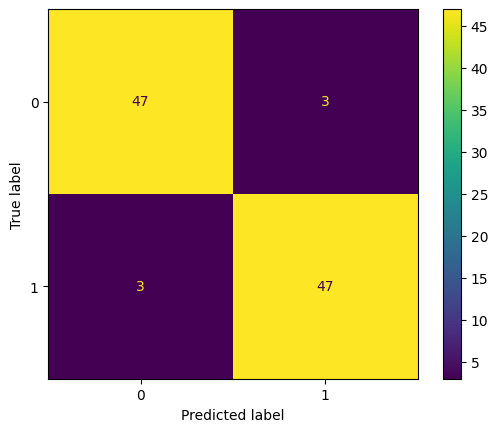

In [26]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

5. COMPARING WITH NAIVE BAYES

In [31]:
#Fit Naive Bayes model on the training data
from sklearn.naive_bayes import GaussianNB

gnb = GaussianNB()
gnb.fit(X_train, y_train)

#Predicting on Naive Bayes
y_pred_gnb = gnb.predict(X_test)

#Evaluation
accuracy_gnb = accuracy_score(y_test, y_pred_gnb)
print(f'Accuracy of naive bayes: {accuracy_gnb:.4f}')

Accuracy of naive bayes: 0.7700


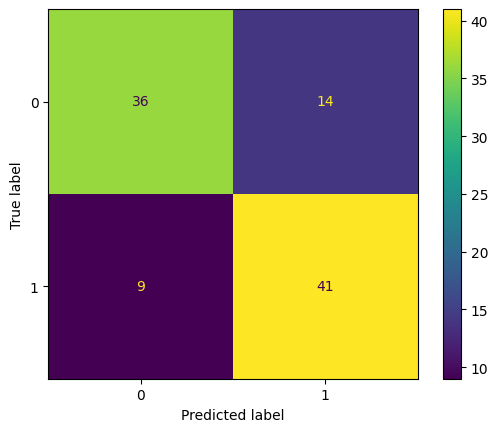

In [32]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gnb)

RESULT EXPLANATION:
1. Accuracy score = 0.94
- The model gets around 94% correct for the test

2. Confusion Matrix
- This aligns with the accuracy score. We have 47 correct for label 1, and 47 correct for label 0.

3. Explain one coefficient means for the odds
- For each one-standard-deviation increase in culmen depth, the odds of a penguin being male are multiplied by about 16, holding species, culmen length, flipper length and body mass fixed.

4. Compare logistic regression with Naive Bayes model
- Logistic regression outperformed Naive Bayes on the same test set (94% vs. 77% accuracy, about 17 more penguins classified correctly). Naive Bayes is more likely to predict Female penguin as Male penguin (14 counts)
- A likely reason is Naive Bayes' independence assumption. The size measurements are strongly correlated, so Naive Bayes counts the same "large penguin" evidence several times, which distorts its probabilities. Logistic regression fits the weights together, so it shares credit among correlated features. That's why flipper length received almost no weight (odds ratio ≈ 1.05) once body mass was included.
- Naive Bayes also models each measurement with a single distribution per sex across all species. Because species differ greatly in size, a heavy female Gentoo can look "male" by Adelie standards (which is in line for the incorrect predictions). Logistic regression's species weights shift its decision boundary for each species, so it can separate males from females within each species.